In [1]:
import pandas as pd
import scipy as sp
import numpy as np
from lightfm import cross_validation
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
from lightfm.evaluation import auc_score
from lightfm import LightFM
import matplotlib.pyplot as plt
import pickle
import os

**Minimal example**

In [2]:
example_data = np.random.randint(2, size=45)
example_data = example_data.reshape(3, 15)
print(example_data)

[[1 1 0 1 0 1 0 0 0 1 0 0 0 0 0]
 [0 0 1 0 0 1 0 0 0 1 0 0 1 0 0]
 [1 1 0 0 0 0 1 1 1 1 1 0 1 1 1]]


In [3]:
example_coo = sp.sparse.coo_matrix(example_data)
(example_train, example_test) = cross_validation.random_train_test_split(example_coo, test_percentage=0.2)
example_train_csr = example_train.tocsr()
example_test_csr = example_test.tocsr()

In [4]:
print(example_train.toarray())

[[1 1 0 0 0 1 0 0 0 1 0 0 0 0 0]
 [0 0 1 0 0 1 0 0 0 0 0 0 1 0 0]
 [0 1 0 0 0 0 1 1 1 0 1 0 1 1 1]]


In [5]:
print(example_test.toarray())

[[0 0 0 1 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 1 0 0 0 0 0]]


In [7]:
example_model = LightFM(no_components=1, loss='warp')
example_model.fit(example_train, epochs=1)

In [12]:
n_rows, n_cols = example_train_csr.shape
train_data_np = example_train.toarray()
test_data_np = example_test.toarray()
ordered_list = []
test_count_list = []
for row in range(n_rows):
    print('row              ', row)
    #known positives in train set
    train_kp = np.where(train_data_np[row]==1)[0]
    print('train_kp         ', train_kp)
    #every DHS index
    full_ind = np.arange(n_cols)
#     print(full_ind)
    #only the DHS indices that are not known positives in the train set
    test_only_ind = np.delete(full_ind, train_kp)
    print('test_only_ind    ', test_only_ind)
    #For each biosample, the DHS values for each DHS that does not exist as known positive in train set
    test_only_data = test_data_np[row, test_only_ind]
    print('test_only_data   ', test_only_data)
    #For each biosample, counting the number of true positives in test set only
    test_only_count = np.sum(test_only_data)
    test_count_list.append(test_only_count)
    print('test_only_count  ', test_only_count)
    #For each biosample, predicting scores for only dhs indices that are not known positives in train set
    scores = example_model.predict(row, test_only_ind)
    print('scores           ', scores)
    #ordering scores
    ordered = np.argsort(-scores)
    print('ordered          ', ordered)
    #ordering DHS values that were not known positives in train set 
    ordered_test_only = test_only_data[ordered]
    print('ordered_test_only', ordered_test_only)
    print()
    ordered_list.append(ordered_test_only)
for k in np.arange(1,16):
    print()
    print('k =', k)
    for row in range(n_rows):
        #for each biosample, calculates precision for the top k DHS recs
        print('precision for row', row, '=', np.sum(ordered_list[row][:k])/k)
        print('recall for row', row, '=', np.sum(ordered_list[row][:k])/test_count_list[row])

row               0
train_kp          [0 1 5 9]
test_only_ind     [ 2  3  4  6  7  8 10 11 12 13 14]
test_only_data    [0 1 0 0 0 0 0 0 0 0 0]
test_only_count   1
scores            [-4.7642130e-01 -2.9874140e-01 -4.1120115e-01 -2.1007031e-01
 -1.8076688e-01 -4.0244693e-01 -2.7896449e-01 -3.4294158e-01
 -2.3562546e-01  4.3179095e-04  5.3627253e-02]
ordered           [10  9  4  3  8  6  1  7  5  2  0]
ordered_test_only [0 0 0 0 0 0 1 0 0 0 0]

row               1
train_kp          [ 2  5 12]
test_only_ind     [ 0  1  3  4  6  7  8  9 10 11 13 14]
test_only_data    [0 0 0 0 0 0 0 1 0 0 0 0]
test_only_count   1
scores            [-0.06476003 -0.06417166 -0.39605483 -0.2700689   0.06416205  0.03133413
 -0.23860697 -0.5149845  -0.29846334 -0.44567373 -0.2707937  -0.23125193]
ordered           [ 4  5  1  0 11  6  3 10  8  2  9  7]
ordered_test_only [0 0 0 0 0 0 0 0 0 0 0 1]

row               2
train_kp          [ 1  6  7  8 10 12 13 14]
test_only_ind     [ 0  2  3  4  5  9 11]
test_only_data

**Calculating precision for example data with LightFM function**

In [15]:
example_precision_list = []
example_recall_list = []
for k_val in np.arange(1, 15):
    example_precision_list.append(precision_at_k(example_model, example_test, train_interactions=example_train, k=k_val))
    example_recall_list.append(recall_at_k(example_model, example_test, train_interactions=example_train, k=k_val))

In [16]:
lightfm_p_mean = np.mean(example_precision_list, axis=1)
print(lightfm_p_mean)
lightfm_r_mean = np.mean(example_recall_list, axis=1)
print()
print(lightfm_r_mean)

[0.         0.16666667 0.11111111 0.08333334 0.06666667 0.05555556
 0.14285715 0.125      0.11111111 0.1        0.09090909 0.11111111
 0.1025641  0.0952381 ]

[0.         0.16666667 0.16666667 0.16666667 0.16666667 0.16666667
 0.66666667 0.66666667 0.66666667 0.66666667 0.66666667 1.
 1.         1.        ]


**Homemade function to calculate precision**

In [17]:
def pr(model, test_data, train_data, k_vals):
    n_rows, n_cols = test_data.shape
    test_data_np = test_data.toarray()
    train_data_np = train_data.toarray()
    ordered_list = []
    test_count_list = []
    for row in range(n_rows):
        #known positives in train set
        train_kp = np.where(train_data_np[row]==1)[0]
        #every DHS index
        full_ind = np.arange(n_cols)
        #only the DHS indices that are not known positives in the train set
        test_only_ind = np.delete(full_ind, train_kp)
        #For each biosample, the DHS values for each DHS that does not exist as known positive in train set
        test_only_data = test_data_np[row, test_only_ind]
        #For each biosample, counting the number of true positives in test set only
        test_only_count = np.sum(test_only_data)
        test_count_list.append(test_only_count)
        #For each biosample, predicting scores for only dhs indices that are not known positives in train set
        scores = model.predict(row, test_only_ind)
        #ordering scores
        ordered = np.argsort(-scores)
        #ordering DHS values that were not known positives in train set 
        ordered_test_only = test_only_data[ordered]
        ordered_list.append(ordered_test_only)
    precision = []
    recall = []
    for k in k_vals:
        k_precision = []
        k_recall = []
        for row in range(n_rows):
#             counts.append(np.mean(ordered_list[row][:k])) #this is how we were going to calculate precision
            #for each biosample, calculates precision for the top k DHS recs
            count = np.sum(ordered_list[row][:k])
            k_precision.append(count/k) #this is how lightFM calculates precision
            k_recall.append(count/test_count_list[row])
        precision.append(k_precision)
        recall.append(k_recall)
    return precision, recall

In [23]:
homemade_precision, homemade_recall = pr(example_model, example_test, example_train, np.arange(1, 15))
homemade_p_mean = np.mean(homemade_precision, axis=1)
homemade_r_mean = np.mean(homemade_recall, axis=1)
print('Homemade Precision:')
print(homemade_p_mean)
print('LightFM Precision:')
print(lightfm_p_mean)
print('Difference between Homemade and LightFM Precision:')
print(np.round(homemade_p_mean - lightfm_p_mean, 9))
print()
print('Homemade Recall:')
print(homemade_r_mean)
print('LightFM Recall:')
print(lightfm_r_mean)
print('Difference between Homemade and LightFM Recall:')
print(np.round(homemade_r_mean - lightfm_r_mean, 9))

Homemade Precision:
[0.         0.16666667 0.11111111 0.08333333 0.06666667 0.05555556
 0.14285714 0.125      0.11111111 0.1        0.09090909 0.11111111
 0.1025641  0.0952381 ]
LightFM Precision:
[0.         0.16666667 0.11111111 0.08333334 0.06666667 0.05555556
 0.14285715 0.125      0.11111111 0.1        0.09090909 0.11111111
 0.1025641  0.0952381 ]
Difference between Homemade and LightFM Precision:
[ 0.e+00 -5.e-09 -1.e-09 -2.e-09 -3.e-09 -0.e+00 -6.e-09  0.e+00 -1.e-09
 -1.e-09 -3.e-09 -1.e-09 -1.e-09 -2.e-09]

Homemade Recall:
[0.         0.16666667 0.16666667 0.16666667 0.16666667 0.16666667
 0.66666667 0.66666667 0.66666667 0.66666667 0.66666667 1.
 1.         1.        ]
LightFM Recall:
[0.         0.16666667 0.16666667 0.16666667 0.16666667 0.16666667
 0.66666667 0.66666667 0.66666667 0.66666667 0.66666667 1.
 1.         1.        ]
Difference between Homemade and LightFM Recall:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [25]:
print(homemade_precision)
print()
print(homemade_recall)

[[0.0, 0.0, 0.0], [0.0, 0.0, 0.5], [0.0, 0.0, 0.3333333333333333], [0.0, 0.0, 0.25], [0.0, 0.0, 0.2], [0.0, 0.0, 0.16666666666666666], [0.14285714285714285, 0.0, 0.2857142857142857], [0.125, 0.0, 0.25], [0.1111111111111111, 0.0, 0.2222222222222222], [0.1, 0.0, 0.2], [0.09090909090909091, 0.0, 0.18181818181818182], [0.08333333333333333, 0.08333333333333333, 0.16666666666666666], [0.07692307692307693, 0.07692307692307693, 0.15384615384615385], [0.07142857142857142, 0.07142857142857142, 0.14285714285714285]]

[[0.0, 0.0, 0.0], [0.0, 0.0, 0.5], [0.0, 0.0, 0.5], [0.0, 0.0, 0.5], [0.0, 0.0, 0.5], [0.0, 0.0, 0.5], [1.0, 0.0, 1.0], [1.0, 0.0, 1.0], [1.0, 0.0, 1.0], [1.0, 0.0, 1.0], [1.0, 0.0, 1.0], [1.0, 1.0, 1.0], [1.0, 1.0, 1.0], [1.0, 1.0, 1.0]]


**Testing Homemade precision and recall function with DHS epochs=15, k=16 dimensions, a=1e-4 model**

In [28]:
pickle_in = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg0001.pickle', 'rb')
model_e15_d16_reg0001=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg0001.pickle', 'rb')
data_e15_d16_reg0001=pickle.load(pickle_in)

In [29]:
n_biosamples, n_DHSs = data_e15_d16_reg0001['test'].shape

In [30]:
p_test_e15_d16_reg0001, r_test_e15_d16_reg0001 = pr(model_e15_d16_reg0001, data_e15_d16_reg0001['test'], data_e15_d16_reg0001['train'], [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs])

In [31]:
p_train_e15_d16_reg0001, r_train_e15_d16_reg0001 = pr(model_e15_d16_reg0001, data_e15_d16_reg0001['train'], data_e15_d16_reg0001['test'], [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs])

In [32]:
print('Test precision @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:')
print(np.mean(p_test_e15_d16_reg0001[0]))
print(np.mean(p_test_e15_d16_reg0001[1]))
print(np.mean(p_test_e15_d16_reg0001[2]))
print(np.mean(p_test_e15_d16_reg0001[3]))
print(np.mean(p_test_e15_d16_reg0001[4]))
print(np.mean(p_test_e15_d16_reg0001[5]))
print(np.mean(p_test_e15_d16_reg0001[6]))
print(np.mean(p_test_e15_d16_reg0001[7]))
print()
print('Train precision @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:')
print(np.mean(p_train_e15_d16_reg0001[0]))
print(np.mean(p_train_e15_d16_reg0001[1]))
print(np.mean(p_train_e15_d16_reg0001[2]))
print(np.mean(p_train_e15_d16_reg0001[3]))
print(np.mean(p_train_e15_d16_reg0001[4]))
print(np.mean(p_train_e15_d16_reg0001[5]))
print(np.mean(p_train_e15_d16_reg0001[6]))
print(np.mean(p_train_e15_d16_reg0001[7]))
print()
print('Test recall @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:')
print(np.mean(r_test_e15_d16_reg0001[0]))
print(np.mean(r_test_e15_d16_reg0001[1]))
print(np.mean(r_test_e15_d16_reg0001[2]))
print(np.mean(r_test_e15_d16_reg0001[3]))
print(np.mean(r_test_e15_d16_reg0001[4]))
print(np.mean(r_test_e15_d16_reg0001[5]))
print(np.mean(r_test_e15_d16_reg0001[6]))
print(np.mean(r_test_e15_d16_reg0001[7]))
print()
print('Train recall @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:')
print(np.mean(r_train_e15_d16_reg0001[0]))
print(np.mean(r_train_e15_d16_reg0001[1]))
print(np.mean(r_train_e15_d16_reg0001[2]))
print(np.mean(r_train_e15_d16_reg0001[3]))
print(np.mean(r_train_e15_d16_reg0001[4]))
print(np.mean(r_train_e15_d16_reg0001[5]))
print(np.mean(r_train_e15_d16_reg0001[6]))
print(np.mean(r_train_e15_d16_reg0001[7]))

Test precision @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:
0.990450204638472
0.9792633015006822
0.9686357435197817
0.9335989085948158
0.5124402455661664
0.11938038199181446
0.019029542974079126
0.005794269672474504

Train precision @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:
0.9986357435197817
0.9972714870395635
0.9927285129604366
0.9883506139154161
0.9299882673942702
0.40594755798090043
0.07612296316507502
0.023177077550453236

Test recall @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:
7.014239846411668e-05
0.0006871112633126575
0.006751147230466397
0.06386829055438017
0.30468423844203674
0.6281848351082219
0.9357322548664392
1.0

Train recall @ [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]:
1.772678e-05
0.00017703885
0.0017546489
0.017424323
0.159253
0.5663845
0.9372475
1.0


In [50]:
#Checking precision @ k=n_DHSs with approximation
test_interactions = data_e15_d16_reg0001['test'].tocsr().size
train_interactions = data_e15_d16_reg0001['train'].tocsr().size
test_interactions_per_line = test_interactions/n_biosamples
train_interactions_per_line = train_interactions/n_biosamples
print('Test Precision @ k=n_DHSs', test_interactions_per_line/n_DHSs)
print('Train Precision @ k=n_DHSs', train_interactions_per_line/n_DHSs)

Test Precision @ k=n_DHSs 0.005794269672474504
Train Precision @ k=n_DHSs 0.023177077550453236


In [35]:
precision_test_mean = []
for i in range(len(p_test_e15_d16_reg0001)):
    precision_test_mean.append(np.mean(p_test_e15_d16_reg0001[i]))
precision_train_mean = []
for i in range(len(p_train_e15_d16_reg0001)):
    precision_train_mean.append(np.mean(p_train_e15_d16_reg0001[i]))    
recall_test_mean = []
for i in range(len(r_test_e15_d16_reg0001)):
    recall_test_mean.append(np.mean(r_test_e15_d16_reg0001[i]))
recall_train_mean = []
for i in range(len(r_train_e15_d16_reg0001)):
    recall_train_mean.append(np.mean(r_train_e15_d16_reg0001[i])) 

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components, a=1e-4)\nk=[1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]')

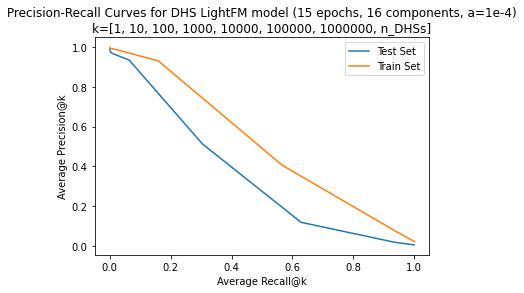

In [41]:
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(recall_test_mean, precision_test_mean)
plt.plot(recall_train_mean, precision_train_mean)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components, a=1e-4)\nk=[1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]')

**Testing precision for individual biosamples**

In [204]:
p1 = pr(model_e15_d16_reg0001, data_e15_d16_reg0001['test'].tocsr()[0, :], data_e15_d16_reg0001['train'].tocsr()[0, :], [1, 10, 100, 1000, 10000])
p2 = pr(model_e15_d16_reg0001, data_e15_d16_reg0001['train'].tocsr()[0, :], data_e15_d16_reg0001['test'].tocsr()[0, :], [1, 10, 100, 1000, 10000])

0
0


In [205]:
p1

[[1.0], [0.9], [0.88], [0.802], [0.3596]]

In [206]:
p2

[[1.0], [1.0], [0.97], [0.973], [0.8462]]